# 06 — 2026-10-18: full run with shuffled options and two follow-up questions, on a GPU

Experiment 05 (notebook 05) on **all 598** Emotions questions, with four changes: the options are shown in a **random
order** (position-bias control), the frames keep the videos' **native resolution** (640x360 or 854x480; earlier runs
shrank them to 448x252 for the CPU), and after the answer the model gets **two separate follow-up questions** about
the evidence it used. A new condition, `T_told`, tells the model that a video exists but is not shown. Same model revision, number of frames, prompt texts and conditions. No system message is sent, so the chat
template adds Qwen's default ("You are a helpful assistant."), as before.

| condition | input | options |
|---|---|---|
| `Q_noE` | question | A–D (floor, comparable to the pilot) |
| `Q` | question | A–E |
| `T` | transcript + question | A–E |
| `T_told` | *"A video of this scene exists, but it is not shown to you."* + T | A–E |
| `VT` | T + 64 silent frames of the question's own clip | A–E |
| `VTmis` | T + 64 silent frames of a clip from a **different film** | A–E |

**Option order.** Each question gets one random order of its five options, *"Cannot tell from the given information."*
included, so it is not always E. The same order is used in all conditions of a question (Q_noE: the same order without
"Cannot tell"), so the conditions differ only in the evidence. Results are stored under the **original** letters
(`prob_A` = the original option A, `prob_E` = "Cannot tell", `answer` = original letter), so the analysis is the same as
in notebook 05. `option_order` and `answer_shown` record what the model saw: `option_order` "CEADB" means the shown A was
the original C, the shown B was "Cannot tell", and so on.

**Follow-ups (two branches).** Each branch is the same chat (the prompt and the model's own top letter as its reply)
plus one question; neither branch sees the other, so the two are independent self-reports.

- **A, free-form:** *"Explain in one sentence which information you based your answer on."* (greedy decoding) → `explanation`
- **B, evidence question:** *"Besides the question and its options, what did you base your answer on?"* with the options
  Nothing else / A transcript / A video / Both a transcript and a video, in a random order per question (the same in
  every condition). Scored like the answer, from the letter probabilities → `evidence_prob_<option>`, `evidence_answer`.
  The question is identical in every condition, so its answers can be compared across conditions: claiming a video in
  Q or T (no video given) is claimed evidence the model never had.

Settings are in `configs/2026-10-18_full_shuffled.toml`. Results are appended to
`outputs/2026-10-18_full_shuffled/results.jsonl`; finished (question, condition) pairs are skipped, so the run can be
stopped and resumed. The model runs on the GPU when there is one. The run uses no answer keys; the analysis loads them, and no cell prints per-question keys.

In [1]:
N_QUESTIONS = None  # None = all 598 questions
CONDITIONS = None  # None = all conditions from the config, or a subset, e.g. ["Q_noE", "Q", "T"]

In [2]:
import sys, json, random, time, tomllib
from pathlib import Path
import pandas as pd
from tqdm.auto import tqdm

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import qwen_omni as qo

CFG_PATH = ROOT / "configs/2026-10-18_full_shuffled.toml"
CFG = tomllib.loads(CFG_PATH.read_text())
CONDITIONS = CONDITIONS or CFG["conditions"]
assert set(CONDITIONS) <= set(CFG["conditions"]), CONDITIONS
EXP_DIR = ROOT / "outputs" / CFG["experiment"]
EXP_DIR.mkdir(parents=True, exist_ok=True)
OUT = EXP_DIR / "results.jsonl"

all_questions = pd.read_parquet(ROOT / "data-private/processed/emotion_questions.parquet")
questions = all_questions.head(N_QUESTIONS)
print(f"{len(questions)} questions, conditions {CONDITIONS} -> {OUT.relative_to(ROOT)}")

598 questions, conditions ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis'] -> outputs/2026-10-18_full_shuffled/results.jsonl


## Mismatched clips

Each question gets the clip of another Emotions question from a **different film**: the one whose clip length is
closest to its own (ties: the earlier one in the fixed order). The pairing is computed over all 598 questions, so it does
not depend on `N_QUESTIONS`. The mismatched clip uses its own frame count (64 for all but the 6 short clips). Only the
video changes: transcript, question and options are the question's own.

In [3]:
mismatch = {}  # question_id -> the question whose clip is shown in VTmis
for q in all_questions.itertuples():
    other = all_questions[all_questions.movie_title != q.movie_title]
    gap = (other.focused_duration_s - q.focused_duration_s).abs()
    mismatch[q.question_id] = other.loc[gap.idxmin()]

pairs = pd.DataFrame({"question_id": list(mismatch),
                      "clip_s": all_questions.focused_duration_s.values,
                      "mis_question_id": [m.question_id for m in mismatch.values()],
                      "mis_movie_title": [m.movie_title for m in mismatch.values()],
                      "mis_clip_s": [m.focused_duration_s for m in mismatch.values()]})
pairs.to_csv(EXP_DIR / "mismatch_pairs.csv", index=False)
print("median |clip length difference| (s):", round((pairs.clip_s - pairs.mis_clip_s).abs().median(), 2))
pairs.head().round(1)

median |clip length difference| (s): 0.05


,question_id,clip_s,mis_question_id,mis_movie_title,mis_clip_s
0,FH-76,21.3,x40a1,MAN TO MAN,21.2
1,97rJU,47.5,ZNAaV,DUSSELDORF,47.6
2,cP4lM,294.0,hjEci,POMMEL,291.1
3,XESWo,55.0,iBIiz,COOL FOR FIVE SECONDS,55.1
4,6p7dK,21.4,kREcQ,THE REFEREE,21.4


## Option order

One fixed random order per question (seeded by `shuffle_seed` and the question id), the same in every condition.
The count below shows how often "Cannot tell" lands on each letter; it should be roughly even. The evidence question
(branch B) gets its own random option order per question, also the same in every condition.

In [4]:
SHOWN = ["A", "B", "C", "D", "E"]  # letters as displayed to the model


def option_order(question_id, with_e=True):
    """The question's option order: original letters in display order. with_e=False drops "Cannot tell" (Q_noE)."""
    order = ["A", "B", "C", "D", "E"]
    random.Random(f"{CFG['shuffle_seed']}-{question_id}").shuffle(order)
    return order if with_e else [x for x in order if x != "E"]


EVIDENCE = CFG["evidence_options"]  # stored name -> option text


def evidence_order(question_id):
    """The question's order of the evidence options (stored names in display order)."""
    order = list(EVIDENCE)
    random.Random(f"{CFG['shuffle_seed']}-{question_id}-evidence").shuffle(order)
    return order


def evidence_prompt(order):
    """Branch B's question, formatted like the main question."""
    options = [f"{shown}. {EVIDENCE[name]}" for shown, name in zip(SHOWN, order)]
    return CFG["evidence_question"] + "\n" + "\n".join(options) + "\n\nAnswer with the option's letter only."


e_position = pd.Series([SHOWN[option_order(qid).index("E")] for qid in all_questions.question_id])
print('"Cannot tell" shown as:', e_position.value_counts().sort_index().to_dict())

"Cannot tell" shown as: {'A': 102, 'B': 106, 'C': 119, 'D': 138, 'E': 133}


## Load the model (~18 GB RAM, a few minutes)

In [5]:
processor, model = qo.load(CFG["model_revision"])
print("device:", model.device)

[transformers] Model config: tts_text_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151860. This may result in unexpected behavior.
[transformers] Model config: tts_text_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151861. This may result in unexpected behavior.
[transformers] Model config: tts_text_pad_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151859. This may result in unexpected behavior.
[transformers] Model config: vision_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151652. This may result in unexpected behavior.
[transformers] Model config: vision_end_token_id must be `None` or an integer within the vocabulary (between 0 and 8447), got 151653. This may result in unexpected behavior.
[transformers] Model config: audio_start_token_id must be `None` or an integer within the vocabulary (between 0 and 8447

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/1346 [00:00<?, ?it/s]

[transformers] Qwen2_5OmniThinkerForConditionalGeneration LOAD REPORT from: Qwen/Qwen2.5-Omni-7B
Key                                                                                                      | Status     |  | 
---------------------------------------------------------------------------------------------------------+------------+--+-
talker.model.layers.{0...23}.mlp.down_proj.weight                                                        | UNEXPECTED |  | 
token2wav.code2wav_bigvgan_model.resblocks.{0...17}.convs1.{0, 1, 2}.weight                              | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transformer_blocks.{0...21}.ff.ff.{0, 3}.weight                             | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transformer_blocks.{0...21}.ff.ff.{0, 3}.bias                               | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transformer_blocks.{0...21}.attn.to_k.bias                                  | UNEXPECTED |  | 
token2wav.code2wav_dit_model.transf

device: cuda:0


## Show the exact prompts for the first question

VT and VTmis have the same text as T, plus the video. The last two blocks are the follow-up branches A and B, shown
with "A" as a placeholder for the model's reply; in the run it is the model's own top letter.

In [6]:
first = questions.iloc[0]
order = option_order(first.question_id)
print("option order:", "".join(order))
for title, text in [("Q_noE", qo.build_prompt(first, with_transcript=False, order=option_order(first.question_id, with_e=False))),
                    ("Q", qo.build_prompt(first, with_transcript=False, option_e=CFG["option_e"], order=order)),
                    ("T_told", CFG["told_note"] + "\n\n" + qo.build_prompt(first, option_e=CFG["option_e"], order=order)),
                    ("T, VT, VTmis", qo.build_prompt(first, option_e=CFG["option_e"], order=order))]:
    print(f"===== {title}")
    print(qo.make_inputs(processor, None, text)[1])
print("===== branch A: free-form explanation (T)")
print(qo.make_inputs(processor, None, text, followup=("A", CFG["explain_prompt"]))[1])
print("===== branch B: evidence question (T)")
print(qo.make_inputs(processor, None, text, followup=("A", evidence_prompt(evidence_order(first.question_id))))[1])

option order: CBEDA
===== Q_noE
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. The man expresses nervousness.
D. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== Q
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
Question: How does the man feel about knocking on the door?
A. The man expresses annoyance.
B. The man expresses fear that there might not be anyone inside.
C. Cannot tell from the given information.
D. The man expresses nervousness.
E. The man expresses sadness that he won't come inside.

Answer with the option's letter only.<|im_end|>
<|im_start|>assistant

===== T_told
<|im_start|>system
You are a helpful assistant.<|im_end|>
<|im_start|>user
A video of this scene exists, but it is n

## Run

For each question and condition: score the letters, take the top one as the answer, then the two follow-up branches
(A: free-form explanation, B: evidence question), append one row.

The progress bar shows the time per question (all five conditions); times 598 gives the length of the full run.

In [7]:
done = {(r["question_id"], r["condition"]) for r in map(json.loads, OUT.open())} if OUT.exists() else set()
print(f"{len(done)} results already in {OUT.name}")

for q in tqdm(questions.itertuples(), total=len(questions), unit="question"):
    for condition in CONDITIONS:
        if (q.question_id, condition) in done:
            continue
        t0 = time.time()

        # text: Q_noE has no option E; Q_noE and Q have no transcript; T_told starts with the note
        option_e = None if condition == "Q_noE" else CFG["option_e"]
        order = option_order(q.question_id, with_e=condition != "Q_noE")
        shown = SHOWN[:len(order)]
        user_text = qo.build_prompt(q._asdict(), with_transcript=condition in ["T", "T_told", "VT", "VTmis"],
                                    option_e=option_e, order=order)
        if condition == "T_told":
            user_text = CFG["told_note"] + "\n\n" + user_text

        # video: the question's own clip (VT) or the mismatched clip (VTmis)
        clip, frames, fps = None, None, None
        if condition == "VT":
            clip = q
        if condition == "VTmis":
            clip = mismatch[q.question_id]
        if clip is not None:
            video = ROOT / "data-private/raw/all_videos" / f"{clip.movie_title}.mp4"
            frames, fps = qo.sample_frames(video, clip.t_i, clip.t_j, int(clip.n_frames), CFG["max_pixels"])

        # 1) score the letters
        inputs, _ = qo.make_inputs(processor, None, user_text, frames, fps)
        r = qo.score_options(model, processor, inputs, shown)
        top = r["prob"].index(max(r["prob"]))
        answer_shown, answer = shown[top], order[top]  # the letter the model gave; the same option in the original order
        t1 = time.time()

        # 2) branch A: the model's answer goes into the chat, then the free-form question
        inputs, _ = qo.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, CFG["explain_prompt"]))
        e = qo.generate_text(model, processor, inputs, CFG["explain_max_new_tokens"])
        t2 = time.time()

        # 3) branch B: the same chat up to the answer, then the evidence question, scored like the answer
        ev_order = evidence_order(q.question_id)
        inputs, _ = qo.make_inputs(processor, None, user_text, frames, fps,
                                   followup=(answer_shown, evidence_prompt(ev_order)))
        ev = qo.score_options(model, processor, inputs, SHOWN[:len(ev_order)])

        row = {"order": q.order, "question_id": q.question_id, "condition": condition,
               **{f"prob_{L}": p for L, p in zip(order, r["prob"])},  # keyed by the original letter
               "mass_on_letters": r["mass_on_letters"], "n_input_tokens": r["n_input_tokens"], "answer": answer, "answer_shown": answer_shown, "option_order": "".join(order),
               "explanation": e["text"], "explanation_tokens": e["n_tokens"], "explanation_hit_limit": e["hit_limit"],
               **{f"evidence_prob_{name}": p for name, p in zip(ev_order, ev["prob"])},
               "evidence_answer": ev_order[ev["prob"].index(max(ev["prob"]))],
               "evidence_order": ",".join(ev_order), "evidence_mass_on_letters": ev["mass_on_letters"],
               "score_seconds": round(t1 - t0, 1), "explain_seconds": round(t2 - t1, 1), "evidence_seconds": round(time.time() - t2, 1),
               "video_question_id": None if clip is None else clip.question_id,
               "n_frames": 0 if frames is None else len(frames),
               "max_pixels": CFG["max_pixels"], "model_revision": CFG["model_revision"], "device": str(model.device)}
        with OUT.open("a") as f:
            f.write(json.dumps(row) + "\n")

60 results already in results.jsonl


  0%|          | 0/598 [00:00<?, ?question/s]

qwen-vl-utils using decord to read video.
[h264 @ 0x55b8082edf40] mmco: unref short failure
[h264 @ 0x55b8082edf40] mmco: unref short failure
[h264 @ 0x55b8082edf40] mmco: unref short failure
[h264 @ 0x55b8082edf40] mmco: unref short failure
[h264 @ 0x55b8082edf40] mmco: unref short failure
[h264 @ 0x55b808224880] mmco: unref short failure
[h264 @ 0x55b8079b4f40] mmco: unref short failure
[h264 @ 0x55b8079b4f40] mmco: unref short failure
[h264 @ 0x55b807adc2c0] mmco: unref short failure
[h264 @ 0x55b808286900] mmco: unref short failure
[h264 @ 0x55b8078f2880] mmco: unref short failure
[h264 @ 0x55b8078f2880] mmco: unref short failure
[h264 @ 0x55b807adc2c0] mmco: unref short failure
[h264 @ 0x55b807adc2c0] mmco: unref short failure
[h264 @ 0x55b8082d9280] mmco: unref short failure
[h264 @ 0x55b8077b2e40] mmco: unref short failure
[h264 @ 0x55b8077b2e40] mmco: unref short failure
[h264 @ 0x55b8077b2e40] mmco: unref short failure
[h264 @ 0x55b8077b2e40] mmco: unref short failure
[h264 @ 

## Results so far

This section reads only the results file and the answer keys. To rerun it without the model, run the first two code
cells, then jump here.

- **answer** = letter with the highest probability (E = abstain)
- **accuracy** = share answered with the correct letter (an abstention counts as not correct)
- **abstain** = share where E is the top letter; **p_E** = probability on E (a softer abstention score)
- **confidence** = top probability among A–D, renormalized over A–D (comparable with the pilot)
- **selective_accuracy** = accuracy on the questions that were not abstained on
- **confidently_wrong** = wrong A–D answer with confidence ≥ `HIGH_CONFIDENCE` (the critical failure), share of all questions

In [8]:
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

HIGH_CONFIDENCE = 0.8
FIGURES = EXP_DIR / "figures"
FIGURES.mkdir(exist_ok=True)

keys = pd.read_parquet(ROOT / "data-private/processed/answer_keys.parquet")[["question_id", "correct_answer_key"]]
info = all_questions[["question_id", "movie_title", "question", "cue_visual_any"]]
df = pd.read_json(OUT, lines=True).drop_duplicates(["question_id", "condition"]).merge(keys, on="question_id").merge(info, on="question_id")

# keep only questions that have every condition run so far, so all conditions are compared on the same questions
n_conditions = df.groupby("question_id").condition.transform("nunique")
df = df[n_conditions == df.condition.nunique()].copy()
conditions = [c for c in CFG["conditions"] if c in set(df.condition)]
print(df.question_id.nunique(), "questions with all of", conditions)

abcd = ["prob_A", "prob_B", "prob_C", "prob_D"]
df["abstain"] = df.answer == "E"
df["p_E"] = df.prob_E.fillna(0)  # Q_noE has no option E
df["correct"] = df.answer == df.correct_answer_key
df["confidence"] = df[abcd].max(axis=1) / df[abcd].sum(axis=1)
df["confidently_wrong"] = ~df.correct & ~df.abstain & (df.confidence >= HIGH_CONFIDENCE)

598 questions with all of ['Q_noE', 'Q', 'T', 'T_told', 'VT', 'VTmis']


In [9]:
summary = df.groupby("condition").agg(
    n=("correct", "size"),
    accuracy=("correct", "mean"),
    abstain=("abstain", "mean"),
    mean_p_E=("p_E", "mean"),
    confidence=("confidence", "mean"),
    confidently_wrong=("confidently_wrong", "mean"),
    mass_on_letters=("mass_on_letters", "mean"),
    score_seconds=("score_seconds", "mean"),
    explain_seconds=("explain_seconds", "mean"),
    evidence_seconds=("evidence_seconds", "mean"),
).reindex(conditions)
summary.insert(3, "selective_accuracy", df[~df.abstain].groupby("condition").correct.mean())
summary.round(3)

,n,accuracy,abstain,selective_accuracy,mean_p_E,confidence,confidently_wrong,mass_on_letters,score_seconds,explain_seconds,evidence_seconds
condition,,,,,,,,,,,
Q_noE,598,0.436,0.000,0.436,0.000,0.699,0.166,1.0,0.006,0.752,0.000
Q,598,0.194,0.617,0.507,0.541,0.700,0.090,1.0,0.000,0.703,0.000
T,598,0.321,0.475,0.611,0.446,0.764,0.120,1.0,0.003,0.766,0.004
T_told,598,0.253,0.619,0.662,0.565,0.759,0.080,1.0,0.005,0.777,0.004
VT,598,0.420,0.294,0.595,0.301,0.801,0.139,1.0,3.998,4.030,3.422
VTmis,598,0.326,0.416,0.559,0.394,0.767,0.151,1.0,3.995,4.023,3.415


Split by whether the annotators tagged a visual cue (face / body). The hypothesis predicts, on visual-cue questions,
more abstention without video (Q, T) than with it (VT), and more abstention with the wrong video (VTmis) than the right one.

In [10]:
df.pivot_table(index="condition", columns="cue_visual_any", values=["correct", "abstain", "p_E", "confidently_wrong"],
               aggfunc="mean").reindex(conditions).round(3)

abstain        confidently_wrong        correct           p_E  \
cue_visual_any   False  True              False  True    False  True   False   
condition                                                                      
Q_noE            0.000  0.000             0.217  0.156   0.413  0.441  0.000   
Q                0.478  0.642             0.130  0.083   0.196  0.194  0.457   
T                0.402  0.488             0.109  0.123   0.370  0.312  0.373   
T_told           0.522  0.636             0.076  0.081   0.326  0.239  0.488   
VT               0.261  0.300             0.207  0.126   0.402  0.423  0.269   
VTmis            0.348  0.429             0.152  0.150   0.348  0.322  0.324   

                       
cue_visual_any  True   
condition              
Q_noE           0.000  
Q               0.556  
T               0.460  
T_told          0.580  
VT              0.306  
VTmis           0.407

### Paired comparisons (same questions)

Wilcoxon signed-rank test on the per-question difference in p_E and in A–D confidence. Only meaningful with enough questions.

In [11]:
wide = df.pivot(index="question_id", columns="condition", values=["p_E", "confidence"])
rows = []
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    if a not in conditions or b not in conditions:
        continue
    for measure in ["p_E", "confidence"]:
        diff = wide[measure][b] - wide[measure][a]
        rows.append({"comparison": f"{b} - {a}", "measure": measure, "n": len(diff),
                     "mean_diff": diff.mean(), "median_diff": diff.median(),
                     "p": wilcoxon(diff).pvalue if (diff != 0).any() else None})
pd.DataFrame(rows).round(4)

,comparison,measure,n,mean_diff,median_diff,p
0,T - Q,p_E,598,-0.0945,-0.0604,0.0000
1,T - Q,confidence,598,0.0633,0.0287,0.0000
2,T_told - T,p_E,598,0.1193,0.0943,0.0000
3,T_told - T,confidence,598,-0.0053,0.0001,0.4503
4,VT - T,p_E,598,-0.1456,-0.0824,0.0000
5,VT - T,confidence,598,0.0376,0.0161,0.0000
6,VTmis - VT,p_E,598,0.0938,0.0354,0.0000
7,VTmis - VT,confidence,598,-0.0344,-0.0119,0.0000
8,VTmis - T,p_E,598,-0.0518,-0.0267,0.0000
9,VTmis - T,confidence,598,0.0032,0.0002,0.7039


### Plot

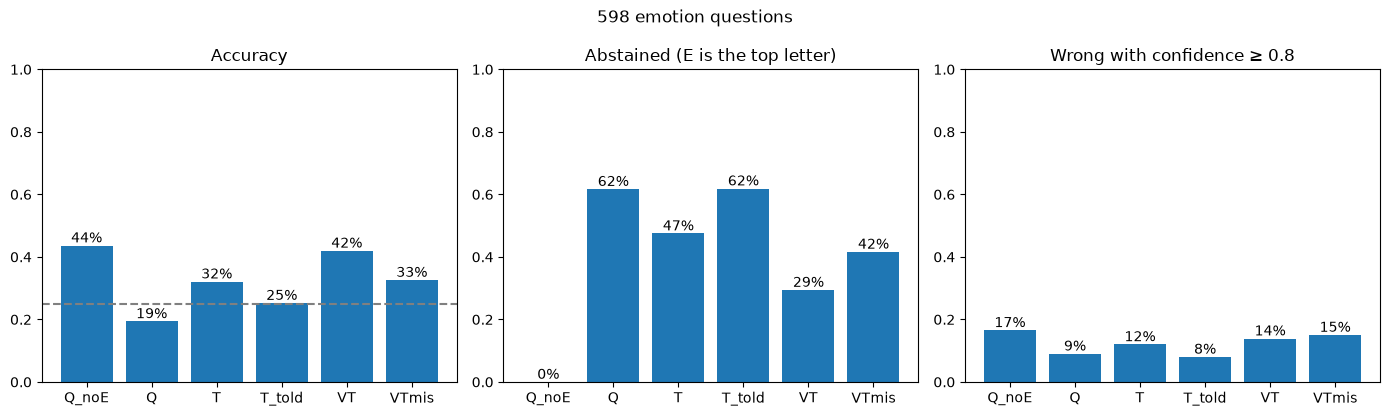

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, col, title in [(axes[0], "accuracy", "Accuracy"),
                       (axes[1], "abstain", "Abstained (E is the top letter)"),
                       (axes[2], "confidently_wrong", f"Wrong with confidence ≥ {HIGH_CONFIDENCE}")]:
    ax.bar(summary.index, summary[col], color="tab:blue")
    for i, value in enumerate(summary[col]):
        ax.text(i, value + 0.01, f"{value:.0%}", ha="center")
    ax.set(title=title, ylim=(0, 1))
axes[0].axhline(0.25, ls="--", c="gray")
fig.suptitle(f"{df.question_id.nunique()} emotion questions")
fig.tight_layout()
fig.savefig(FIGURES / "summary_by_condition.png", dpi=200)
plt.show()

### More plots

Shared style and helpers. Colors: blue for a single series; blue and orange when two groups are compared.
Error bars are 95% intervals: bootstrap over questions for means, Wilson for proportions.

In [13]:
import numpy as np

BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e4e2dc"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": MUTED,
                     "axes.labelcolor": INK, "axes.titlecolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "axes.axisbelow": True,
                     "font.size": 11, "legend.frameon": False})

def bootstrap_ci(values, n_resamples=2000, seed=0):
    """95% bootstrap interval for the mean (resampling questions)."""
    rng = np.random.default_rng(seed)
    values = np.asarray(values, dtype=float)
    means = [rng.choice(values, len(values)).mean() for _ in range(n_resamples)]
    return np.percentile(means, [2.5, 97.5])

def wilson(k, n, z=1.96):
    """95% interval for a proportion k/n."""
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * (p * (1 - p) / n + z**2 / (4 * n**2)) ** 0.5 / (1 + z**2 / n)
    return centre - half, centre + half

# extra columns used by the plots
df["forced_answer"] = df[abcd].idxmax(axis=1).str[-1]  # best of A-D, ignoring E
df["forced_correct"] = df.forced_answer == df.correct_answer_key
df["no_dialogue"] = df.question_id.map(all_questions.set_index("question_id").focused_n_words) == 0
df["outcome"] = np.where(df.abstain, "abstain", np.where(df.correct, "right", "wrong"))
with_e = [c for c in conditions if c != "Q_noE"]

#### 1. Abstention follows the evidence

Mean P(E) and the share of questions where E is the top letter, from the least evidence (question only) to the most
(question + transcript + the right video), and with the wrong video.

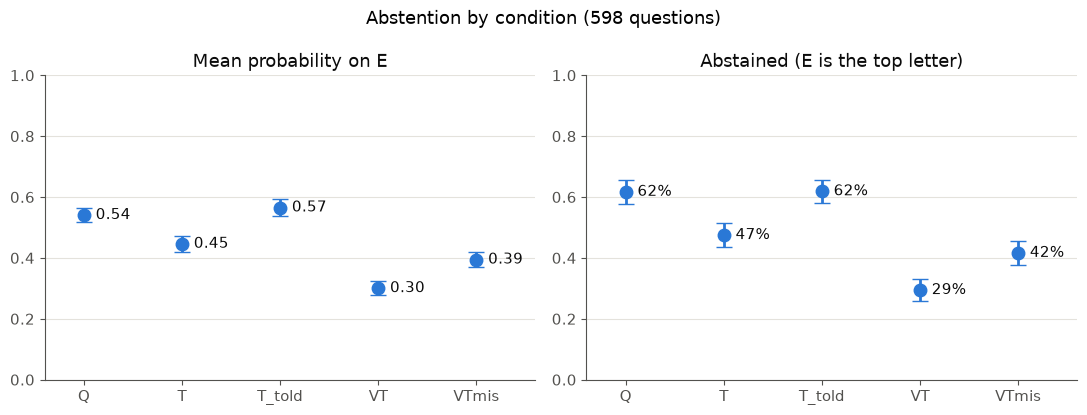

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, title in zip(axes, ["Mean probability on E", "Abstained (E is the top letter)"]):
    for i, condition in enumerate(with_e):
        g = df[df.condition == condition]
        if title.startswith("Mean"):
            value, (lo, hi) = g.p_E.mean(), bootstrap_ci(g.p_E)
        else:
            value, (lo, hi) = g.abstain.mean(), wilson(g.abstain.sum(), len(g))
        ax.errorbar(i, value, yerr=[[value - lo], [hi - value]], fmt="o", ms=9, color=BLUE, capsize=6, lw=2)
        ax.text(i + 0.12, value, f"{value:.2f}" if title.startswith("Mean") else f"{value:.0%}", va="center", color=INK)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.4, len(with_e) - 0.4), title=title)
fig.suptitle(f"Abstention by condition ({df.question_id.nunique()} questions)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_by_condition.png", dpi=200)
plt.show()

#### 2. The video changes *whether* the model answers, not *what* it answers

Each bar splits all questions into four outcomes. Solid: the model answered (right or wrong). Hatched: it abstained;
the hatch color shows whether its best A–D option would have been right or wrong. If the video gave better evidence,
VT would have more solid blue than T *and* a better ratio of blue to orange among the answered questions.

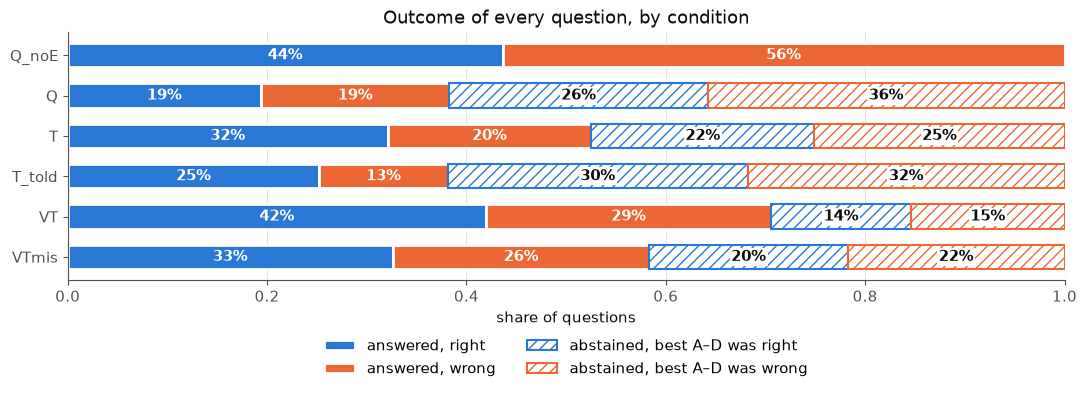

accuracy among answered: {'Q_noE': 0.436, 'Q': 0.507, 'T': 0.611, 'T_told': 0.662, 'VT': 0.595, 'VTmis': 0.559}
forced A-D accuracy:    {'Q_noE': 0.441, 'Q': 0.453, 'T': 0.547, 'T_told': 0.552, 'VT': 0.562, 'VTmis': 0.525}


In [15]:
parts = [("answered, right", ~df.abstain & df.correct, BLUE, None),
         ("answered, wrong", ~df.abstain & ~df.correct, ORANGE, None),
         ("abstained, best A–D was right", df.abstain & df.forced_correct, BLUE, "///"),
         ("abstained, best A–D was wrong", df.abstain & ~df.forced_correct, ORANGE, "///")]

fig, ax = plt.subplots(figsize=(11, 4.2))
rows = np.arange(len(conditions))
left = np.zeros(len(conditions))
for label, mask, color, hatch in parts:
    share = mask.groupby(df.condition).mean().reindex(conditions).values
    hatched = hatch is not None
    keep = share > 0  # skip empty segments (e.g. no abstentions in Q_noE)
    ax.barh(rows[keep], share[keep], left=left[keep], color="white" if hatched else color, edgecolor=color if hatched else "white",
            hatch=hatch, linewidth=1.5 if hatched else 2, label=label, height=0.6)
    for y, (x, w) in enumerate(zip(left, share)):
        if w >= 0.06:
            ax.text(x + w / 2, y, f"{w:.0%}", ha="center", va="center", color=INK if hatched else "white",
                    fontweight="bold", bbox=dict(facecolor="white", edgecolor="none", pad=1) if hatched else None)
    left += share
ax.set_yticks(rows, conditions)
ax.invert_yaxis()
ax.set(xlim=(0, 1), xlabel="share of questions", title="Outcome of every question, by condition")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", color=GRID)
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.18))
fig.tight_layout()
fig.savefig(FIGURES / "outcomes_by_condition.png", dpi=200)
plt.show()

print("accuracy among answered:", df[~df.abstain].groupby("condition").correct.mean().reindex(conditions).round(3).to_dict())
print("forced A-D accuracy:   ", df.groupby("condition").forced_correct.mean().reindex(conditions).round(3).to_dict())

#### 3. Question by question: P(E) with and without the (right) video

One dot per question. Above the diagonal: more abstention in the second condition. Left: adding the video (T → VT).
Right: swapping in the wrong video (VT → VTmis).

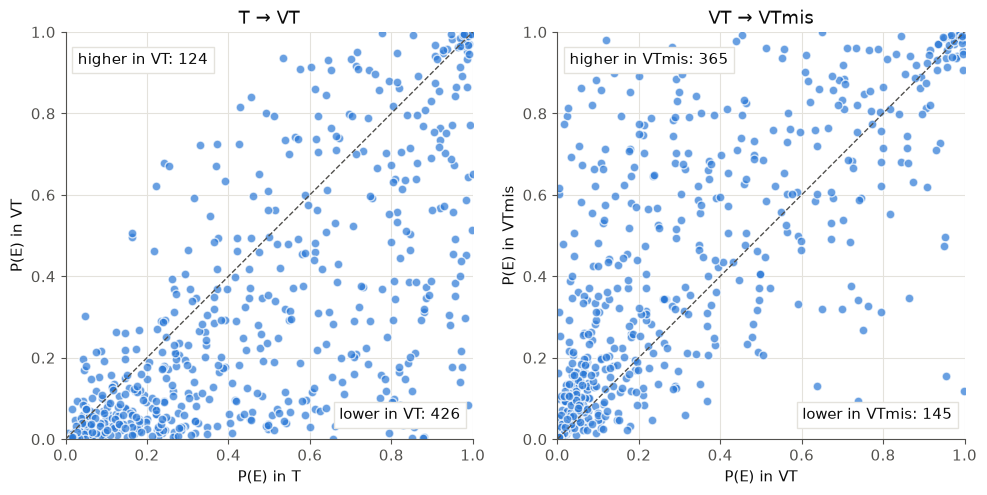

In [16]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, (a, b) in zip(axes, [("T", "VT"), ("VT", "VTmis")]):
    ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls="--")
    ax.scatter(pE[a], pE[b], s=40, color=BLUE, alpha=0.7, edgecolor="white", linewidth=1)
    up, down = (pE[b] > pE[a] + 0.01).sum(), (pE[b] < pE[a] - 0.01).sum()
    ax.text(0.03, 0.95, f"higher in {b}: {up}", transform=ax.transAxes, va="top", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.text(0.97, 0.05, f"lower in {b}: {down}", transform=ax.transAxes, ha="right", color=INK, bbox=dict(facecolor="white", edgecolor=GRID))
    ax.set(xlim=(0, 1), ylim=(0, 1), aspect="equal", xlabel=f"P(E) in {a}", ylabel=f"P(E) in {b}", title=f"{a} → {b}")
    ax.grid(axis="both", color=GRID)
fig.tight_layout()
fig.savefig(FIGURES / "p_E_per_question.png", dpi=200)
plt.show()

#### 4. Where the answers move

Counts of questions by outcome in one condition (rows) and another (columns). The diagonal is "no change".

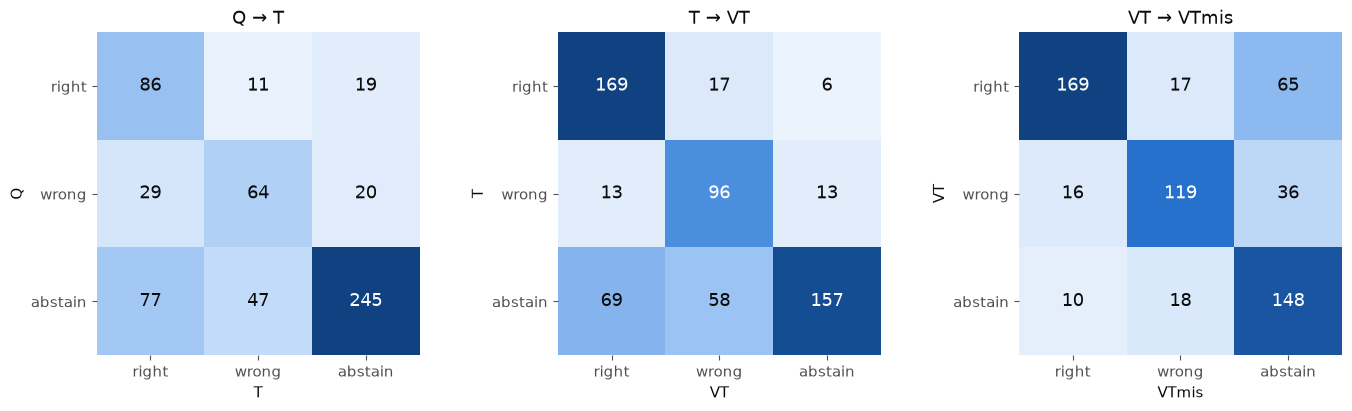

In [17]:
from matplotlib.colors import LinearSegmentedColormap

blues = LinearSegmentedColormap.from_list("blues", ["#f5f9fe", "#9ec5f4", "#2a78d6", "#104281"])
outcome = df.pivot(index="question_id", columns="condition", values="outcome")
labels = ["right", "wrong", "abstain"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for ax, (a, b) in zip(axes, [("Q", "T"), ("T", "VT"), ("VT", "VTmis")]):
    table = pd.crosstab(outcome[a], outcome[b]).reindex(index=labels, columns=labels, fill_value=0)
    ax.imshow(table.values, cmap=blues, vmin=0, vmax=table.values.max())
    for i in range(3):
        for j in range(3):
            n = table.values[i, j]
            ax.text(j, i, n, ha="center", va="center", fontsize=13,
                    color="white" if n > table.values.max() * 0.55 else INK)
    ax.set(xticks=range(3), xticklabels=labels, yticks=range(3), yticklabels=labels,
           xlabel=b, ylabel=a, title=f"{a} → {b}")
    ax.grid(False)
    ax.spines[:].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "outcome_transitions.png", dpi=200)
plt.show()

#### 5. Subgroups: visual-cue tag and clips without dialogue

Abstention rate across conditions for each subgroup. Groups are small (see n in the labels), so read these as
patterns, not results.

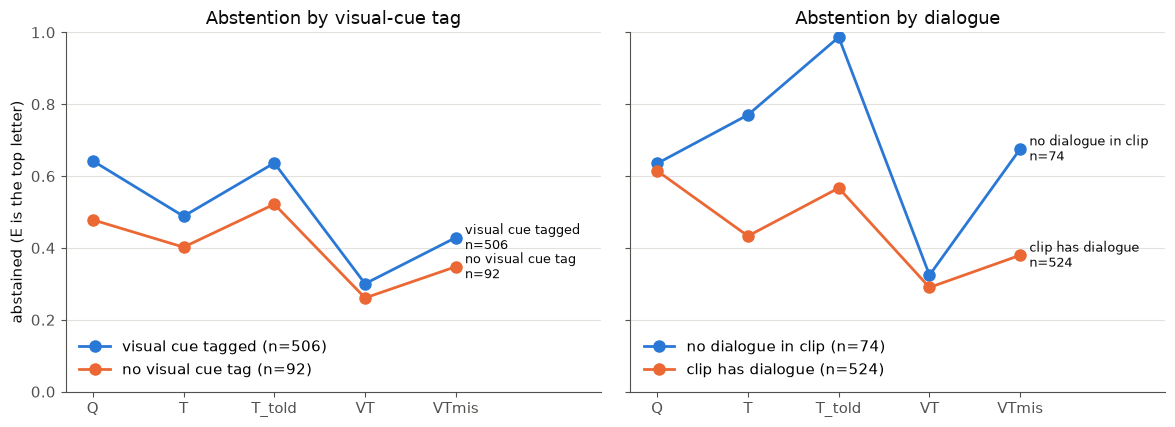

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, (column, names) in zip(axes, [("cue_visual_any", {True: "visual cue tagged", False: "no visual cue tag"}),
                                      ("no_dialogue", {False: "clip has dialogue", True: "no dialogue in clip"})]):
    for value, color in [(True, BLUE), (False, ORANGE)]:
        g = df[(df[column] == value) & df.condition.isin(with_e)]
        rate = g.groupby("condition").abstain.mean().reindex(with_e)
        n = g.question_id.nunique()
        ax.plot(range(len(with_e)), rate.values, "o-", color=color, lw=2, ms=8, label=f"{names[value]} (n={n})")
        ax.text(len(with_e) - 1 + 0.1, rate.values[-1], f"{names[value]}\nn={n}", va="center", color=INK, fontsize=9)
    ax.set(xticks=range(len(with_e)), xticklabels=with_e, ylim=(0, 1), xlim=(-0.3, len(with_e) + 0.6),
           title=f"Abstention by {'visual-cue tag' if column == 'cue_visual_any' else 'dialogue'}")
    ax.legend(loc="lower left")
axes[0].set_ylabel("abstained (E is the top letter)")
fig.tight_layout()
fig.savefig(FIGURES / "abstention_subgroups.png", dpi=200)
plt.show()

## Explanations

One row per question and condition, also saved as `explanations.csv` in the experiment folder for reading or hand coding.
No answer keys are saved here or shown below (only aggregate scores use them), so the file can be in git.

In [19]:
explanations = df[["order", "question_id", "movie_title", "question", "condition", "option_order", "answer_shown", "answer",
                   "confidence", "p_E", "explanation", "evidence_answer", "explanation_hit_limit"]].sort_values(["order", "condition"])
explanations.to_csv(EXP_DIR / "explanations.csv", index=False)
print("explanations that hit the token limit:", explanations.explanation_hit_limit.sum())
pd.set_option("display.max_colwidth", None)
explanations.head(15)

explanations that hit the token limit: 0


,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit
1,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q,CBEDA,C,E,0.749128,0.613288,The answer is based on the information that there is no specific emotion or sentiment expressed by the man regarding knocking on the door in the given context.,nothing,False
0,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,Q_noE,CBDA,B,B,0.671428,0.000000,"The answer is based on the man expressing fear that there might not be anyone inside, which indicates uncertainty and potential disappointment.",nothing,False
2,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T,CBEDA,C,E,0.864958,0.832706,"The information is based on the fact that the man is knocking on the door, which implies that he is trying to get someone's attention, but there is no dialogue to indicate his feelings about it.",transcript,False
3,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,T_told,CBEDA,C,E,0.589316,0.979086,"The answer is based on the fact that there is no dialogue provided in the transcript, making it impossible to determine the man's feelings about knocking on the door.",transcript,False
4,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VT,CBEDA,B,B,0.997395,0.147719,The man expresses fear that there might not be anyone inside.,transcript,False
5,0,FH-76,REELING ISAAC,How does the man feel about knocking on the door?,VTmis,CBEDA,B,B,0.997215,0.047300,The man expresses fear that there might not be anyone inside.,transcript,False
7,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q,CDAEB,C,A,0.824093,0.232639,"The answer is based on the information that the young woman steps back, indicating she feels scared and wants to avoid further violence.",nothing,False
6,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,Q_noE,CDAB,C,A,0.860223,0.000000,"The answer is based on the information that the young woman steps back, indicating her fear of being hurt again.",nothing,False
8,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T,CDAEB,C,A,0.924394,0.079174,The information is based on the young woman's action of stepping back after the older woman's violent reaction.,transcript,False
9,1,97rJU,SWING FOR THE FENCES,How does the young woman feel about the older woman's violent reaction?,T_told,CDAEB,C,A,0.948369,0.126971,The information is based on the older woman's violent reaction and the young woman's response of stepping back.,transcript,False


### First look: does the model claim visual evidence it did not have?

A crude keyword screen for words about faces, expressions or body language. Such words in **Q / T** (no video) or in
**VTmis** (video from another film) describe evidence the model did not have. This is only a quick look; the real
analysis needs the explanations coded by hand (or by an LLM judge).

In [20]:
VISUAL_WORDS = ["face", "facial", "expression", "smile", "smiling", "frown", "eyes", "gaze", "tears", "crying",
                "body language", "posture", "gesture", "video", "visible"]
pattern = r"\b(?:" + "|".join(VISUAL_WORDS) + r")\b"
explanations["mentions_visual"] = explanations.explanation.str.contains(pattern, case=False)
display(explanations.groupby("condition").mentions_visual.mean().reindex(conditions).round(3))
explanations[(explanations.condition == "VTmis") & explanations.mentions_visual & (explanations.answer != "E")].head(10)

condition
Q_noE     0.129
Q         0.090
T         0.094
T_told    0.134
VT        0.204
VTmis     0.191
Name: mentions_visual, dtype: float64

,order,question_id,movie_title,question,condition,option_order,answer_shown,answer,confidence,p_E,explanation,evidence_answer,explanation_hit_limit,mentions_visual
41,6,IESLM,MARYAM JOON,Why does the young woman touch the fruit to her face?,VTmis,ACBED,E,D,0.995341,0.020240,The information is based on the description of the young woman touching the fruit to her face and then smiling.,transcript,False,True
113,18,l91Zi,PULL,How does the girl feel when she locks eyes with the man,VTmis,DBECA,E,A,0.826685,0.391662,The information is based on the girl's expression and the context of the scene.,transcript,False,True
119,19,nDSVR,A SECRET JOURNEY,How is the protagonist feeling in this moment?,VTmis,AEDBC,D,B,0.985477,0.117675,"The information is based on the dialogue where the protagonist expresses her discomfort with the current situation, mentioning the vomiting, shitting blood, and crying, indicating anxiety about her situation.",transcript,False,True
137,22,UoFUT,SOMETHING LIKE LONELINESS,What is the woman's emotional progression during the conversation?,VTmis,DECBA,D,B,0.473737,0.106967,"The woman's initial neutral reaction, followed by embarrassment, and then nervousness are evident from her body language and facial expressions.",transcript,False,True
167,27,0f5zd,HEAD ABOVE WATER,What does the man feel as the woman touches his face?,VTmis,BAECD,A,B,0.613757,0.134336,The man feels grief and complete disappointment because he is crying and his eyes are red.,transcript,False,True
215,35,tWgjm,GET READY WITH ME,Why is the man in olive green seated in front of the desktop moving his cursor between video thumbnails without clicking any of them?\n,VTmis,EACBD,B,A,0.886920,0.107168,"The information is based on the man's actions of moving the cursor between video thumbnails without clicking any of them, which suggests indecision and a struggle to commit to any of the options, reflecting his inner turmoil.",transcript,False,True
293,48,_aNhQ,ITALIAN MIRACLE,What is the woman feeling when she smiles?,VTmis,BCAED,E,D,0.978268,0.022489,The information is based on the woman's smile and the context of the dialogue.,transcript,False,True
383,63,E0aVA,MY BROTHER IS A MERMAID,Why is the woman in white hanging up the glittery pants on the clothesline she had previously thrown into the bin?,VTmis,CABED,C,B,0.765357,0.066458,"The information is based on the scene where the woman in white is seen hanging up the glittery pants on the clothesline, indicating a shift in her perspective towards her son's personal expression.",transcript,False,True
605,100,GjedE,THE ARK,What is the emotion the black man goes through after hearing the white woman's command,VTmis,ECBAD,E,D,0.503775,0.307757,"The information is based on the fact that the black man is crying, which indicates he feels scared.",transcript,False,True
623,103,9ItLe,ARI,Which two emotions does the boy feel for the girl playing basketball?,VTmis,DCBEA,A,D,0.986978,0.434600,The boy is watching the girl play basketball and he is smiling.,transcript,False,True


#### 6. What the explanations talk about

Share of explanations per condition that (a) use words about faces, expressions or body language, (b) refer to the
transcript or dialogue, (c) say the information is not enough. Keyword screens only; (a) in Q_noE, Q and T is
visual evidence the model never had.

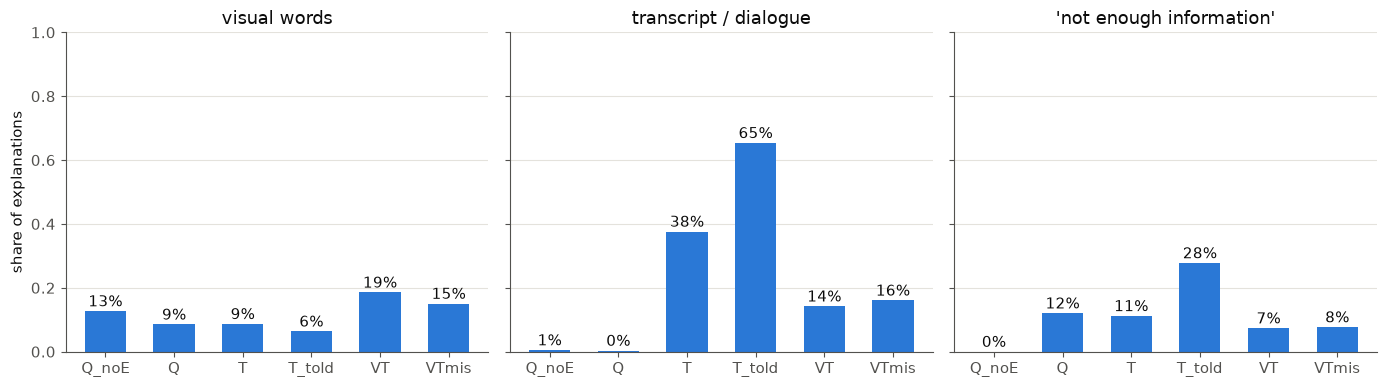

In [21]:
screens = {
    "visual words": r"\b(?:face|facial|expression|smil\w*|frown\w*|eyes|gaze|tears|cry\w*|body language|posture|gesture\w*)\b",
    "transcript / dialogue": r"\b(?:transcript|dialogue|says|said)\b",
    "'not enough information'": r"does not provide|not enough|cannot be determined|impossible to determine|no (?:information|dialogue|context)",
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4), sharey=True)
for ax, (title, pattern) in zip(axes, screens.items()):
    share = explanations.explanation.str.contains(pattern, case=False).groupby(explanations.condition).mean().reindex(conditions)
    ax.bar(conditions, share.values, color=BLUE, width=0.6)
    for i, v in enumerate(share.values):
        ax.text(i, v + 0.015, f"{v:.0%}", ha="center", color=INK)
    ax.set(title=title, ylim=(0, 1))
axes[0].set_ylabel("share of explanations")
fig.tight_layout()
fig.savefig(FIGURES / "explanation_screens.png", dpi=200)
plt.show()

## Told that a video exists (T_told vs T)

Does the model hold back more when it is told that a video exists but is not shown? A model sensitive to evidence
should abstain more in T_told mainly on the questions where the video matters, not on all questions. As a proxy, the
video "mattered" when the answer in VT differs from the answer in T. A rise of the same size in both groups is a
reaction to the sentence, not to the missing evidence.

In [22]:
if {"T", "T_told", "VT"} <= set(conditions):
    answers = df.pivot(index="question_id", columns="condition", values="answer")
    video_mattered = (answers["VT"] != answers["T"]).rename("video_mattered")
    told = df[df.condition.isin(["T", "T_told"])].merge(video_mattered, left_on="question_id", right_index=True)
    display(told.pivot_table(index="video_mattered", columns="condition", values=["abstain", "p_E"], aggfunc="mean").round(3))
    print("questions per group:", video_mattered.value_counts().to_dict())

abstain           p_E       
condition            T T_told      T T_told
video_mattered                             
False            0.380  0.533  0.404  0.515
True             0.686  0.811  0.540  0.677

questions per group: {False: 413, True: 185}


## Evidence question (branch B)

Share of each answer to *"Besides the question and its options, what did you base your answer on?"*, per condition.
What the model actually had: Q_noE and Q nothing else, T and T_told a transcript, VT and VTmis both. A video (or both)
claimed in Q_noE, Q, T or T_told is evidence it never had (in T_told, right after being told the video is not shown). The second table splits by whether the model abstained, since after an
abstention the question reads as "what led you to abstain". `evidence_mass_on_letters` checks that the model answered
with a letter at all.

In [23]:
evidence_names = list(EVIDENCE)
display(pd.crosstab(df.condition, df.evidence_answer, normalize="index")
        .reindex(index=conditions, columns=evidence_names, fill_value=0).round(3))
display(pd.crosstab([df.condition, df.abstain], df.evidence_answer, normalize="index")
        .reindex(columns=evidence_names, fill_value=0).round(3))
claims_video = df.evidence_answer.isin(["video", "both"])
print("claimed a video:", claims_video.groupby(df.condition).mean().reindex(conditions).round(3).to_dict())
print("mean evidence_mass_on_letters:", round(df.evidence_mass_on_letters.mean(), 3))

evidence_answer,nothing,transcript,video,both
condition,,,,
Q_noE,0.550,0.358,0.038,0.054
Q,0.784,0.187,0.017,0.012
T,0.099,0.896,0.003,0.002
T_told,0.149,0.851,0.000,0.000
VT,0.089,0.846,0.018,0.047
VTmis,0.192,0.784,0.007,0.017


evidence_answer    nothing  transcript  video   both
condition abstain                                   
Q         False      0.555       0.380  0.035  0.031
          True       0.927       0.068  0.005  0.000
Q_noE     False      0.550       0.358  0.038  0.054
T         False      0.010       0.981  0.006  0.003
          True       0.197       0.803  0.000  0.000
T_told    False      0.000       1.000  0.000  0.000
          True       0.241       0.759  0.000  0.000
VT        False      0.005       0.919  0.019  0.057
          True       0.290       0.670  0.017  0.023
VTmis     False      0.011       0.954  0.009  0.026
          True       0.446       0.546  0.004  0.004

claimed a video: {'Q_noE': 0.092, 'Q': 0.028, 'T': 0.005, 'T_told': 0.0, 'VT': 0.065, 'VTmis': 0.023}
mean evidence_mass_on_letters: 1.0


## Option position

Does the letter an option is shown as matter? Left: abstention rate by the letter "Cannot tell" was shown as. Without
position bias the rates are similar across letters. Right: share of answers by the letter given.

In [24]:
e_conditions = [c for c in conditions if c != "Q_noE"]
df["e_shown_as"] = df.option_order.str.find("E").map(dict(enumerate(SHOWN)))  # NaN for Q_noE
display(df[df.condition.isin(e_conditions)]
        .pivot_table(index="condition", columns="e_shown_as", values="abstain", aggfunc="mean")
        .reindex(e_conditions).round(3))
display(pd.crosstab(df.condition, df.answer_shown, normalize="index").reindex(conditions).round(3))

e_shown_as,A,B,C,D,E
condition,,,,,
Q,0.529,0.594,0.672,0.609,0.662
T,0.441,0.415,0.504,0.507,0.489
T_told,0.569,0.623,0.655,0.609,0.632
VT,0.353,0.274,0.261,0.297,0.293
VTmis,0.392,0.406,0.420,0.428,0.429


answer_shown,A,B,C,D,E
condition,,,,,
Q_noE,0.289,0.271,0.244,0.196,0.000
Q,0.184,0.181,0.219,0.206,0.211
T,0.181,0.167,0.229,0.212,0.211
T_told,0.164,0.184,0.222,0.217,0.212
VT,0.229,0.192,0.197,0.182,0.199
VTmis,0.194,0.199,0.199,0.199,0.209


## Run time

In [25]:
seconds = df.score_seconds + df.explain_seconds + df.evidence_seconds
display(seconds.groupby(df.condition).mean().reindex(conditions).round(1).rename("seconds per question"))
print(f"{seconds.sum() / 3600:.1f} GPU-hours for {df.question_id.nunique()} questions (model loading not included)")

condition
Q_noE      0.8
Q          0.7
T          0.8
T_told     0.8
VT        11.4
VTmis     11.4
Name: seconds per question, dtype: float64

4.3 GPU-hours for 598 questions (model loading not included)


## Additional tests

Added after the run (2026-10-19), from the results file only; used in the 19.10 slides.

- Abstention, paired: exact McNemar test on the questions that start or stop abstaining between two conditions.
- T_told: is the rise in P(E) larger where the video mattered (VT answer ≠ T answer)? Mann–Whitney test.
- Option position: does abstention depend on the letter "Cannot tell" is shown as? Chi-square test per condition;
  and, without "Cannot tell" (Q_noE), are the shown letters chosen equally often?
- T_told explanations: how many mention the video the prompt said exists.

In [ ]:
from scipy.stats import binomtest, chi2_contingency, chisquare, mannwhitneyu

abstained = df.pivot(index="question_id", columns="condition", values="abstain")
for condition in e_conditions:
    lo, hi = wilson(abstained[condition].sum(), len(abstained))
    print(f"{condition:7} abstained {abstained[condition].mean():.1%}  95% CI [{lo:.1%}, {hi:.1%}]")
print()
for a, b in [("Q", "T"), ("T", "T_told"), ("T", "VT"), ("VT", "VTmis"), ("T", "VTmis")]:
    start = int((~abstained[a] & abstained[b]).sum())
    stop = int((abstained[a] & ~abstained[b]).sum())
    print(f"{a} -> {b}: {start} start abstaining, {stop} stop; exact McNemar p = {binomtest(start, start + stop).pvalue:.2g}")

Q       abstained 61.7%  95% CI [57.7%, 65.5%]
T       abstained 47.5%  95% CI [43.5%, 51.5%]
T_told  abstained 61.9%  95% CI [57.9%, 65.7%]
VT      abstained 29.4%  95% CI [25.9%, 33.2%]
VTmis   abstained 41.6%  95% CI [37.8%, 45.6%]

Q -> T: 39 start abstaining, 124 stop; exact McNemar p = 1.6e-11
T -> T_told: 87 start abstaining, 1 stop; exact McNemar p = 5.8e-25
T -> VT: 19 start abstaining, 127 stop; exact McNemar p = 8.4e-21
VT -> VTmis: 101 start abstaining, 28 stop; exact McNemar p = 7e-11
T -> VTmis: 47 start abstaining, 82 stop; exact McNemar p = 0.0026


In [ ]:
pE = df.pivot(index="question_id", columns="condition", values="p_E")
answers = df.pivot(index="question_id", columns="condition", values="answer")
video_mattered = answers["VT"] != answers["T"]
rise = pE["T_told"] - pE["T"]
print(f"P(E) rise T -> T_told: video mattered {rise[video_mattered].mean():+.3f} (n = {video_mattered.sum()}), "
      f"did not {rise[~video_mattered].mean():+.3f} (n = {(~video_mattered).sum()}); "
      f"Mann-Whitney p = {mannwhitneyu(rise[video_mattered], rise[~video_mattered]).pvalue:.2g}")

P(E) rise T -> T_told: video mattered +0.137 (n = 185), did not +0.111 (n = 413); Mann-Whitney p = 0.00018


In [ ]:
for condition in e_conditions:
    g = df[df.condition == condition]
    p = chi2_contingency(pd.crosstab(g.e_shown_as, g.abstain))[1]
    print(f"abstention vs letter of 'Cannot tell', {condition}: chi-square p = {p:.2g}")
letters = df[df.condition == "Q_noE"].answer_shown.value_counts().reindex(["A", "B", "C", "D"])
print(f"Q_noE answers by shown letter: {letters.to_dict()}; chi-square vs equal p = {chisquare(letters).pvalue:.2g}")

abstention vs letter of 'Cannot tell', Q: chi-square p = 0.18
abstention vs letter of 'Cannot tell', T: chi-square p = 0.55
abstention vs letter of 'Cannot tell', T_told: chi-square p = 0.75
abstention vs letter of 'Cannot tell', VT: chi-square p = 0.63
abstention vs letter of 'Cannot tell', VTmis: chi-square p = 0.98
Q_noE answers by shown letter: {'A': 173, 'B': 162, 'C': 146, 'D': 117}; chi-square vs equal p = 0.0078


In [ ]:
told = df[df.condition == "T_told"]
mentions_video = told.explanation.str.contains(r"\bvideo", case=False)
print(f"T_told explanations mentioning the video: {mentions_video.mean():.1%} "
      f"(abstentions {mentions_video[told.abstain].mean():.1%}, answers {mentions_video[~told.abstain].mean():.1%})")

T_told explanations mentioning the video: 7.5% (abstentions 11.4%, answers 1.3%)
